In [1]:
import pandas as pd
df = pd.read_csv("paris_listings.csv")
df.head()

,listing_id,neighbourhood,room_type,property_type,latitude,longitude,accommodates,bedrooms,beds,price,minimum_nights,availability_365,number_of_reviews,number_of_reviews_ltm,reviews_per_month,review_scores_rating,host_is_superhost,calculated_host_listings_count
0,4266398,Passy,Entire home/apt,Entire rental unit,48.85125,2.27371,2,1.0,1.0,110.37,30.0,188,3,1,0.22,5.00,False,8
1,7793559,Palais-Bourbon,Entire home/apt,Entire rental unit,48.85938,2.31105,2,1.0,1.0,241.00,1.0,328,3,0,0.11,4.33,False,65
2,8258872,Bourse,Private room,Private room in rental unit,48.86813,2.35247,7,2.0,6.0,289.75,3.0,165,266,46,2.95,4.85,True,16
3,9299834,Panthéon,Entire home/apt,Entire rental unit,48.84610,2.35203,4,2.0,3.0,323.50,1.0,70,11,9,0.80,4.82,False,1
4,9909361,Vaugirard,Entire home/apt,Entire rental unit,48.83163,2.30231,3,2.0,2.0,173.00,2.0,268,17,17,2.30,4.94,True,1


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28108 entries, 0 to 28107
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   listing_id                      28108 non-null  int64  
 1   neighbourhood                   28108 non-null  object 
 2   room_type                       28108 non-null  object 
 3   property_type                   28108 non-null  object 
 4   latitude                        28108 non-null  float64
 5   longitude                       28108 non-null  float64
 6   accommodates                    28108 non-null  int64  
 7   bedrooms                        28103 non-null  float64
 8   beds                            27175 non-null  float64
 9   price                           28108 non-null  float64
 10  minimum_nights                  28010 non-null  float64
 11  availability_365                28108 non-null  int64  
 12  number_of_reviews               

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
listing_id,28108.0,5.506014e+06,2.599772e+06,1.000358e+06,3.254932e+06,5.514730e+06,7.775756e+06,9.999630e+06
latitude,28108.0,4.886340e+01,1.695723e-02,4.881614e+01,4.885160e+01,4.886448e+01,4.887583e+01,4.890159e+01
longitude,28108.0,2.342293e+00,3.221439e-02,2.233870e+00,2.322320e+00,2.346560e+00,2.364060e+00,2.464910e+00
accommodates,28108.0,3.393233e+00,1.831312e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,1.600000e+01
bedrooms,28103.0,1.274668e+00,8.903446e-01,0.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,3.300000e+01
beds,27175.0,1.901932e+00,1.163141e+00,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00,3.000000e+01
price,28108.0,2.716769e+02,2.007488e+02,4.000000e+01,1.420000e+02,2.140000e+02,3.326700e+02,1.500000e+03
minimum_nights,28010.0,5.752124e+00,1.848031e+01,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,3.650000e+02
availability_365,28108.0,1.922142e+02,1.188277e+02,0.000000e+00,7.700000e+01,2.120000e+02,3.060000e+02,3.650000e+02
number_of_reviews,28108.0,5.569656e+01,9.066478e+01,1.000000e+00,9.000000e+00,2.700000e+01,6.500000e+01,4.760000e+03


In [4]:
df.isna().sum()

listing_id                          0
neighbourhood                       0
room_type                           0
property_type                       0
latitude                            0
longitude                           0
accommodates                        0
bedrooms                            5
beds                              933
price                               0
minimum_nights                     98
availability_365                    0
number_of_reviews                   0
number_of_reviews_ltm               0
reviews_per_month                   0
review_scores_rating                0
host_is_superhost                   0
calculated_host_listings_count      0
dtype: int64

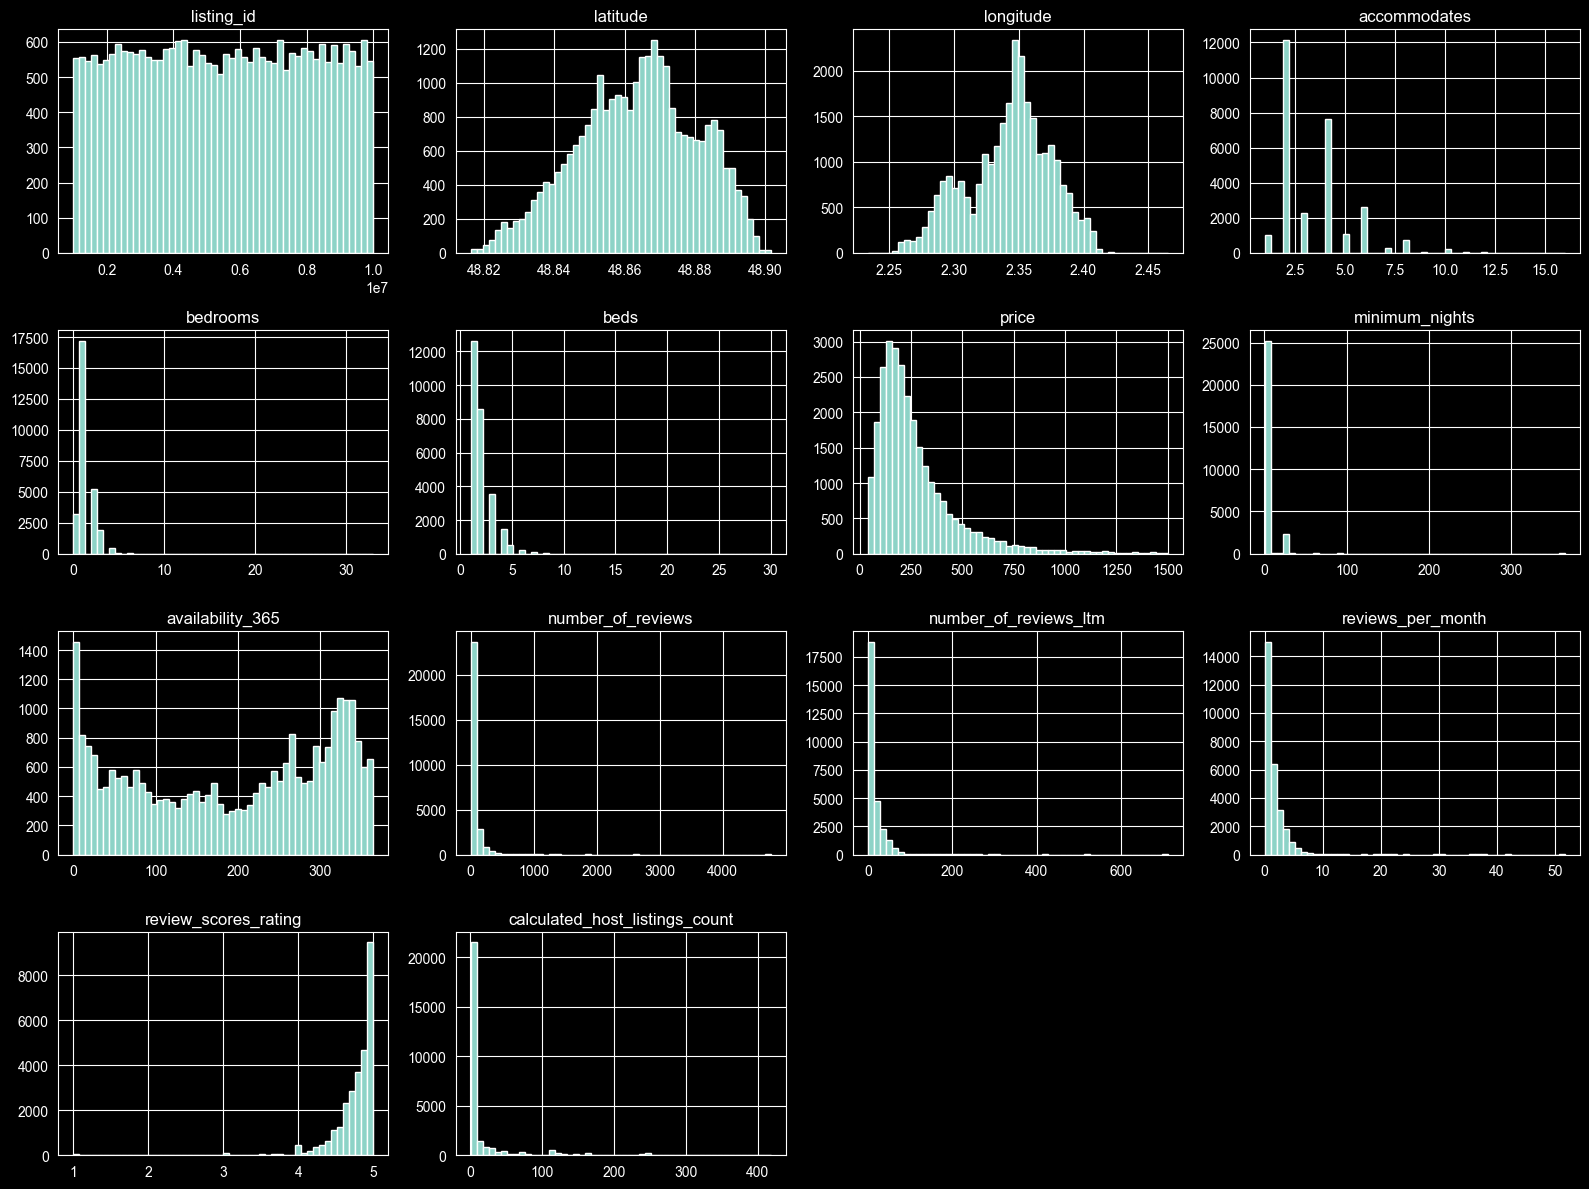

In [5]:
import matplotlib.pyplot as plt
df.hist(bins=50, figsize=(16, 12))
plt.tight_layout()
plt.show()

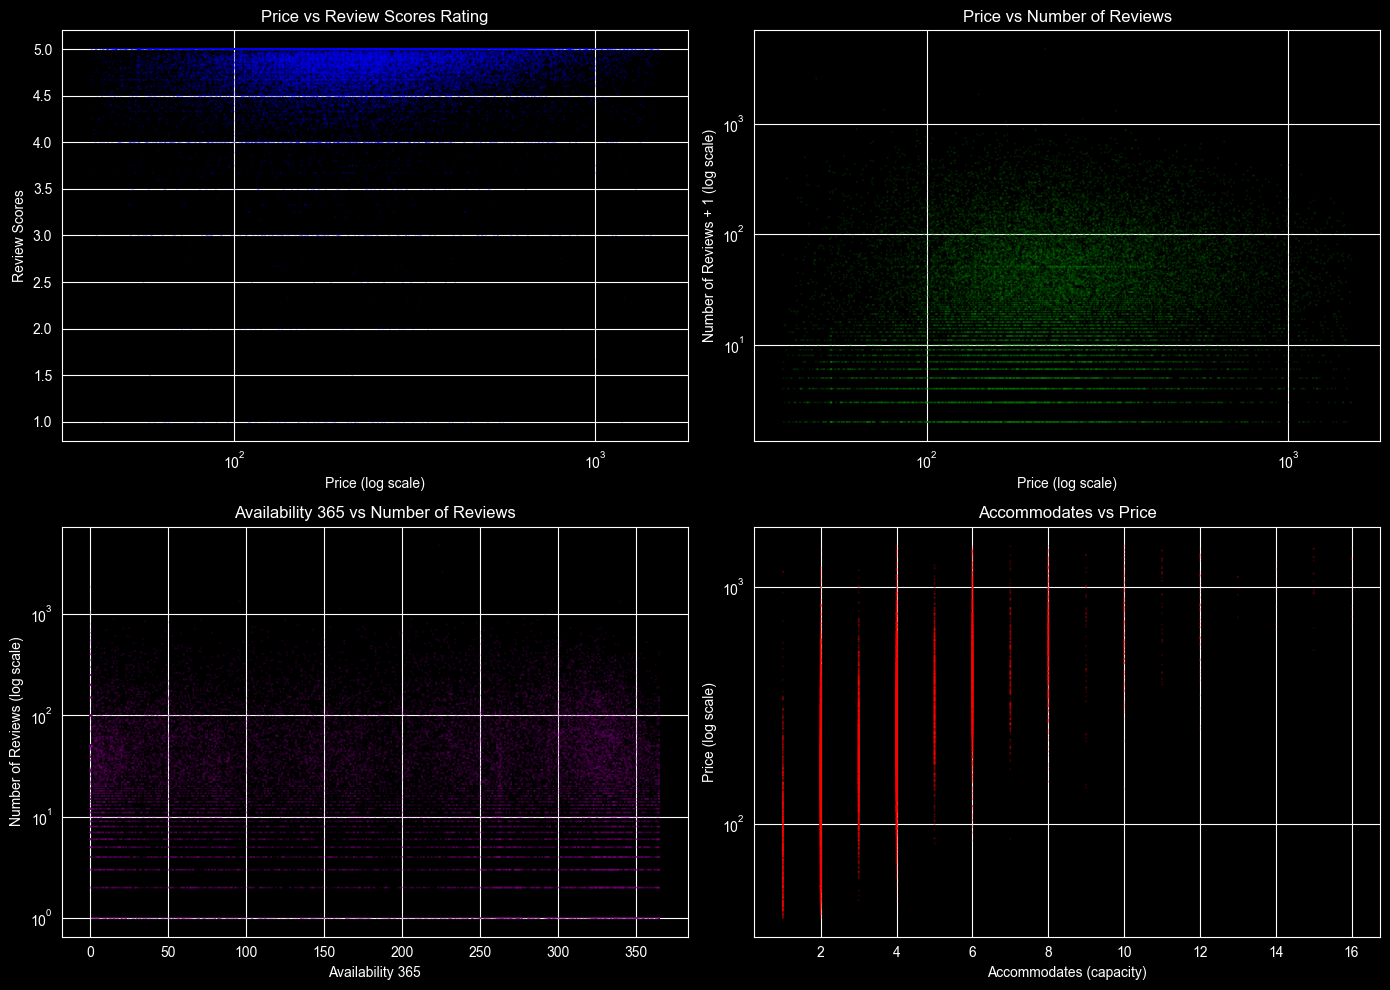

In [6]:
marker_params = {'s': 2, 'alpha': 0.2, 'edgecolors': 'none'}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# График 1: Price (логарифм) vs Review Scores Rating
axes[0, 0].scatter(df['price'], df['review_scores_rating'], color='blue', **marker_params)
axes[0, 0].set_xscale('log')
axes[0, 0].set_title('Price vs Review Scores Rating')
axes[0, 0].set_xlabel('Price (log scale)')
axes[0, 0].set_ylabel('Review Scores')

# График 2: Price (логарифм) vs Number of Reviews (логарифм)
# Чтобы избежать ошибки log(0), прибавляем 1 к отзывам
axes[0, 1].scatter(df['price'], df['number_of_reviews'] + 1, color='green', **marker_params)
axes[0, 1].set_xscale('log')
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Price vs Number of Reviews')
axes[0, 1].set_xlabel('Price (log scale)')
axes[0, 1].set_ylabel('Number of Reviews + 1 (log scale)')

# График 3: Availability 365 vs Number of Reviews
axes[1, 0].scatter(df['availability_365'], df['number_of_reviews'], color='purple', **marker_params)
axes[1, 0].set_yscale('log') # Отзывов может быть очень много у единиц, лог-шкала полезна
axes[1, 0].set_title('Availability 365 vs Number of Reviews')
axes[1, 0].set_xlabel('Availability 365')
axes[1, 0].set_ylabel('Number of Reviews (log scale)')

# График 4: Accommodates vs Price (логарифм)
axes[1, 1].scatter(df['accommodates'], df['price'], color='red', **marker_params)
axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Accommodates vs Price')
axes[1, 1].set_xlabel('Accommodates (capacity)')
axes[1, 1].set_ylabel('Price (log scale)')

plt.tight_layout()
plt.show()

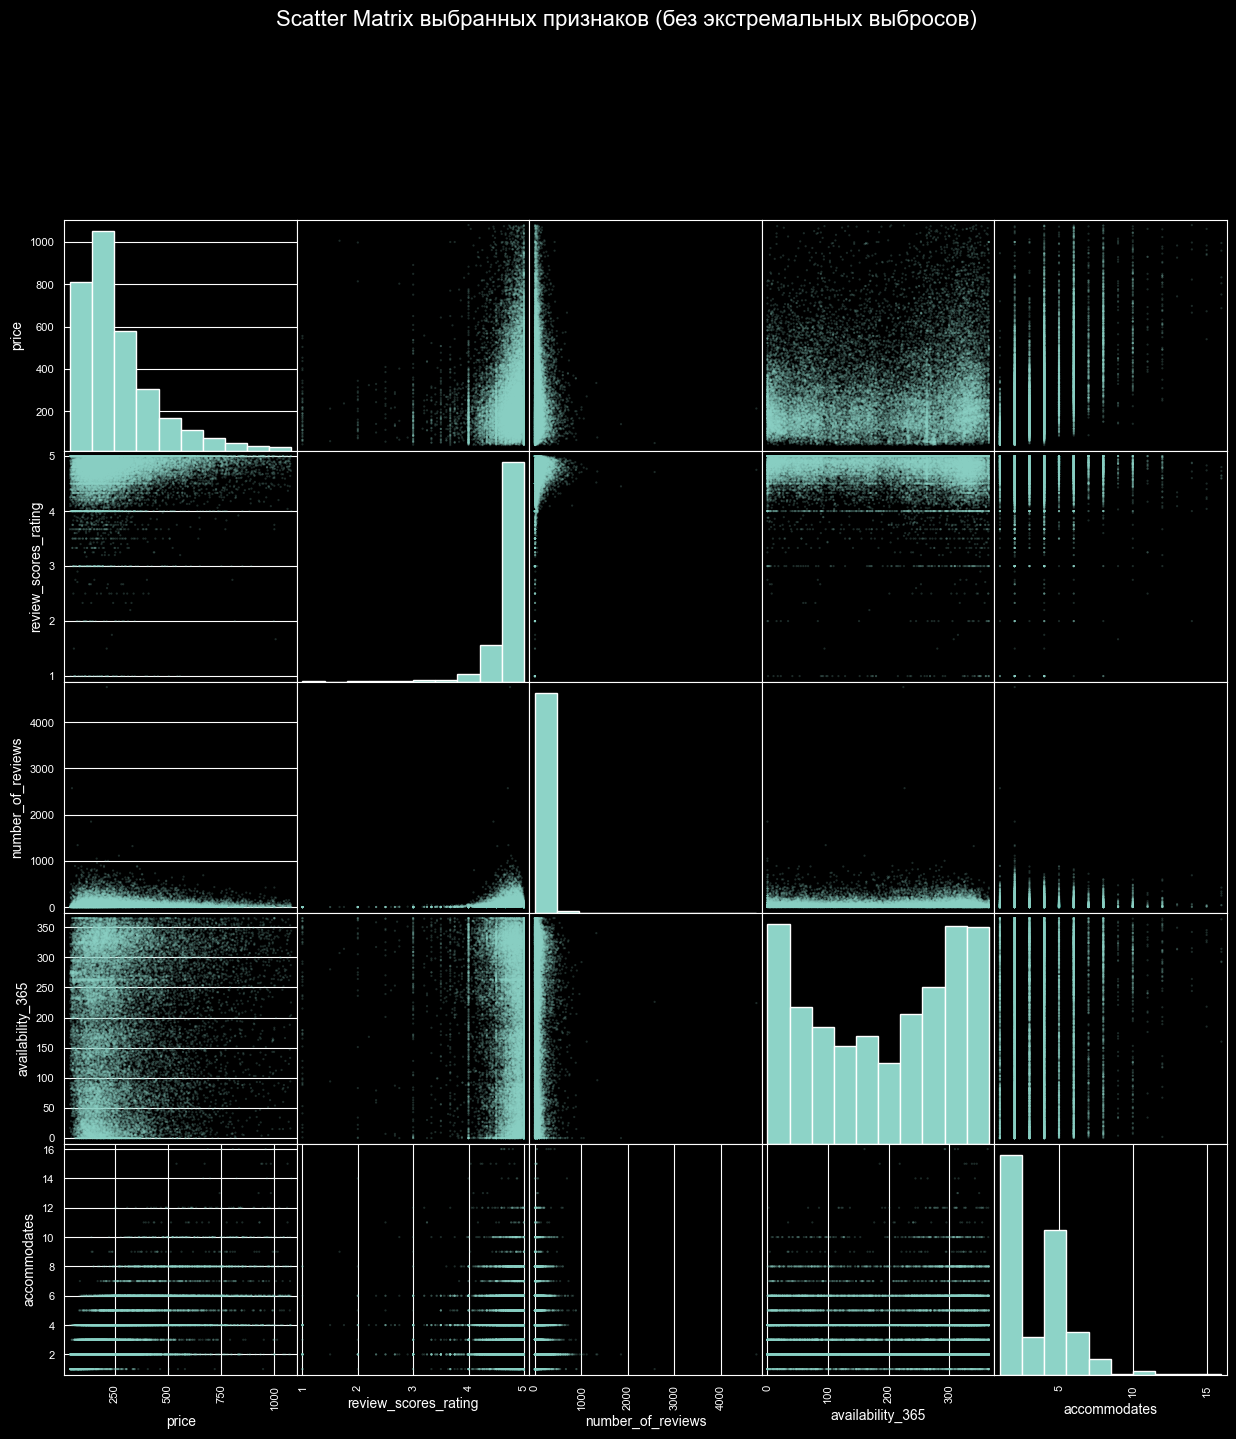

In [7]:
cols_to_plot = [
    'price',
    'review_scores_rating',
    'number_of_reviews',
    'availability_365',
    'accommodates'
]


price_cap = df['price'].quantile(0.99)
df_matrix = df[df['price'] <= price_cap].copy()

# Строим матрицу рассеяния
pd.plotting.scatter_matrix(
    df_matrix[cols_to_plot],
    alpha=0.2,
    figsize=(15, 15),
    diagonal='hist', # на диагонали будут гистограммы распределения
    marker='.',
    s=10 # для scatter_matrix размер задается немного иначе, s=10 для '.' даст нужный эффект
)

plt.suptitle('Scatter Matrix выбранных признаков (без экстремальных выбросов)', y=1.02, fontsize=16)
plt.show()

In [8]:
logical_error_mask = df["number_of_reviews_ltm"] > df["number_of_reviews"]
alien_rows_logical = df[logical_error_mask]
print(f"Строк с логической ошибкой в отзывах: {len(alien_rows_logical)}")

Строк с логической ошибкой в отзывах: 0


In [9]:
cols_to_check = ['review_scores_rating', 'reviews_per_month', 'price']

for col in cols_to_check:
    if col in df.columns:
        valid_data = df[col].dropna()
        precision_diff = (valid_data != valid_data.round(2)).sum()
        print(f"Столбец '{col}': {precision_diff} значений имеют больше двух знаков после запятой")

Столбец 'review_scores_rating': 0 значений имеют больше двух знаков после запятой
Столбец 'reviews_per_month': 0 значений имеют больше двух знаков после запятой
Столбец 'price': 0 значений имеют больше двух знаков после запятой


In [10]:
cats_to_check = ['neighbourhood', 'room_type', 'property_type', 'host_is_superhost']

for col in cats_to_check:
    print(f"\n--- Распределение в {col} ---")
    print(df[col].value_counts(dropna=False))


--- Распределение в neighbourhood ---
neighbourhood
Popincourt             2576
Buttes-Montmartre      2376
Vaugirard              2336
Entrepôt               1850
Batignolles-Monceau    1718
Temple                 1653
Opéra                  1627
Passy                  1518
Bourse                 1506
Hôtel-de-Ville         1196
Buttes-Chaumont        1163
Ménilmontant           1075
Reuilly                1062
Élysée                 1035
Panthéon                995
Luxembourg              980
Observatoire            890
Louvre                  888
Palais-Bourbon          863
Gobelins                801
Name: count, dtype: int64

--- Распределение в room_type ---
room_type
Entire home/apt    24804
Private room        3109
Hotel room           131
Shared room           64
Name: count, dtype: int64

--- Распределение в property_type ---
property_type
Entire rental unit                    23125
Private room in rental unit            1590
Room in hotel                           888
Entir

In [11]:
print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов по координатам (latitude, longitude):", df.duplicated(subset=['latitude', 'longitude']).sum())
print("Дубликатов по метрикам:", df.duplicated(subset=['price', 'review_scores_rating', 'number_of_reviews']).sum())

Полных дубликатов строк: 0
Дубликатов по координатам (latitude, longitude): 1873
Дубликатов по метрикам: 766


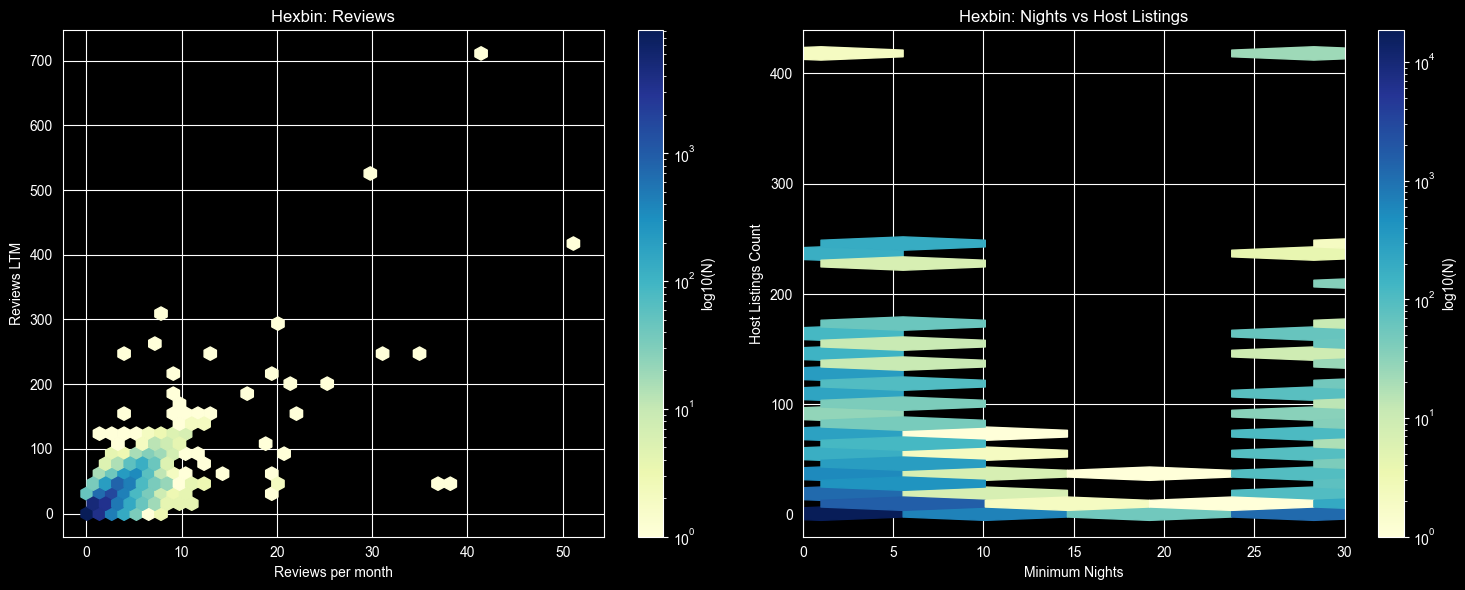

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

hb1 = axes[0].hexbin(df['reviews_per_month'], df['number_of_reviews_ltm'],
                     gridsize=40, cmap='YlGnBu', bins='log')
axes[0].set_xlabel('Reviews per month')
axes[0].set_ylabel('Reviews LTM')
axes[0].set_title('Hexbin: Reviews')
fig.colorbar(hb1, ax=axes[0], label='log10(N)')

hb2 = axes[1].hexbin(df['minimum_nights'], df['calculated_host_listings_count'],
                     gridsize=40, cmap='YlGnBu', bins='log')

axes[1].set_xlim(0, 30)
axes[1].set_xlabel('Minimum Nights')
axes[1].set_ylabel('Host Listings Count')
axes[1].set_title('Hexbin: Nights vs Host Listings')
fig.colorbar(hb2, ax=axes[1], label='log10(N)')

plt.tight_layout()
plt.show()

In [13]:
df['lat_precision'] = df['latitude'].astype(str).apply(lambda x: len(x.split('.')[1]) if '.' in x else 0)
df['lon_precision'] = df['longitude'].astype(str).apply(lambda x: len(x.split('.')[1]) if '.' in x else 0)

print("Уникальные длины хвостов latitude:\n", df['lat_precision'].value_counts())
print("\nУникальные длины хвостов longitude:\n", df['lon_precision'].value_counts())

df_sorted = df.sort_values('listing_id')
id_diff = df_sorted['listing_id'].diff()
print("\nТоп-10 частых интервалов между listing_id:\n", id_diff.value_counts().head(10))

Уникальные длины хвостов latitude:
 lat_precision
5    25212
4     2587
3      280
2       29
Name: count, dtype: int64

Уникальные длины хвостов longitude:
 lon_precision
5    25313
4     2525
3      241
2       25
1        4
Name: count, dtype: int64

Топ-10 частых интервалов между listing_id:
 listing_id
30.0    102
13.0    101
20.0    100
12.0     97
26.0     95
43.0     95
54.0     92
9.0      91
21.0     90
19.0     90
Name: count, dtype: int64


In [14]:
mask_missing = df['beds'].isna() | df['bedrooms'].isna() | df['minimum_nights'].isna()
df_missing = df[mask_missing]

print(f"Строк с целевыми пропусками: {len(df_missing)}")

if len(df_missing) > 0:
    print("\nРаспределение room_type у строк с пропусками:")
    print(df_missing['room_type'].value_counts(normalize=True).round(3))
    print("\nРаспределение review_scores_rating у строк с пропусками:")
    print(df_missing['review_scores_rating'].value_counts(dropna=False).head())

Строк с целевыми пропусками: 977

Распределение room_type у строк с пропусками:
room_type
Private room       0.536
Entire home/apt    0.448
Hotel room         0.015
Name: proportion, dtype: float64

Распределение review_scores_rating у строк с пропусками:
review_scores_rating
5.00    279
4.50     41
4.67     32
4.75     28
4.71     24
Name: count, dtype: int64


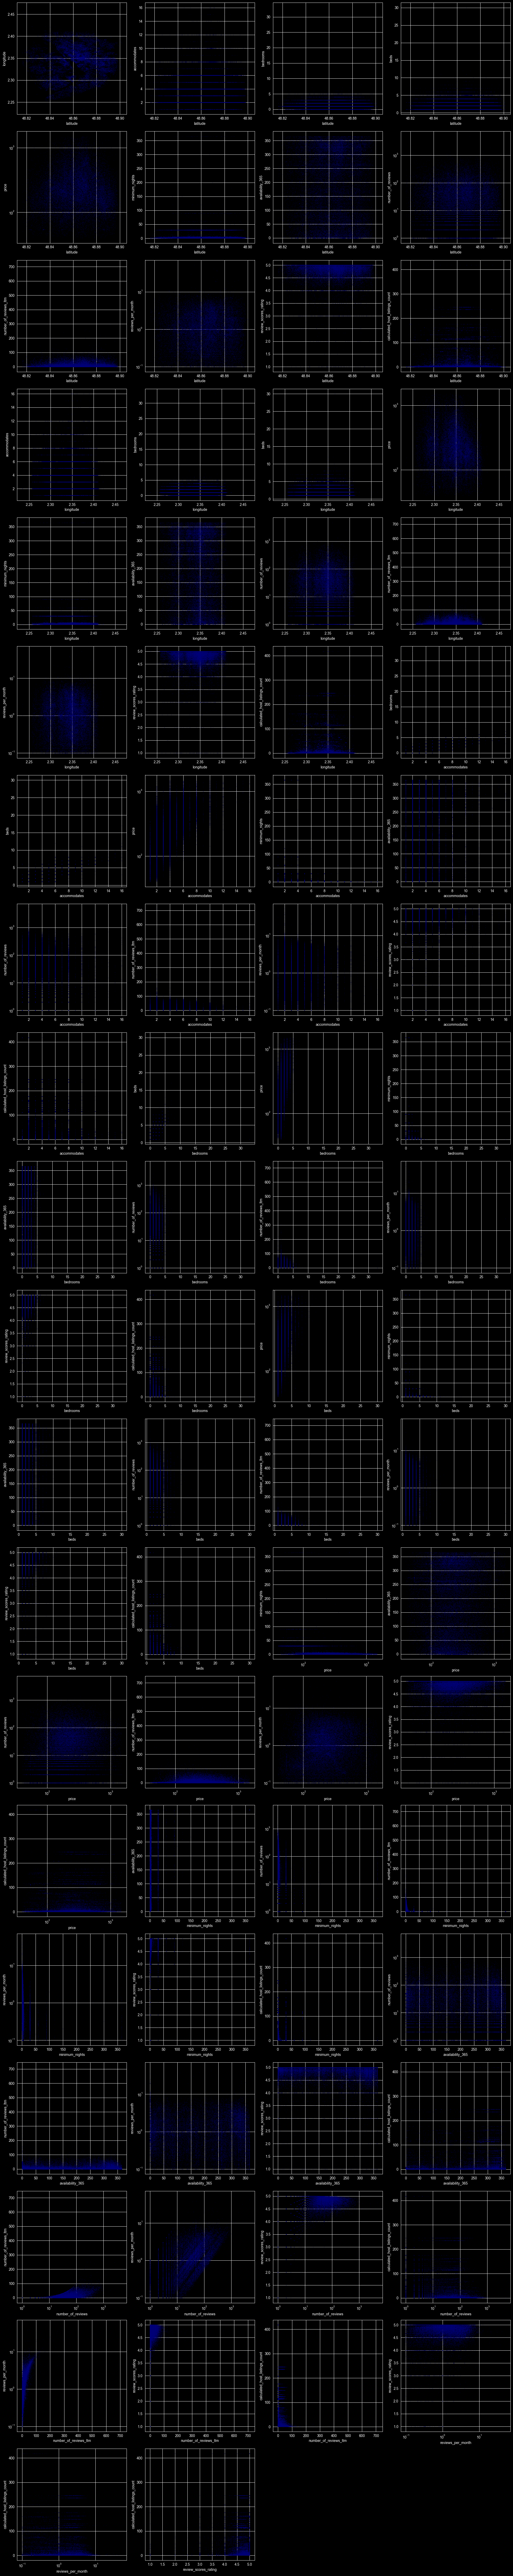

In [15]:
import itertools

num_cols = df.select_dtypes(include=['float64', 'int64']).columns.drop(
    ['listing_id', 'lat_precision', 'lon_precision'], errors='ignore'
)

pairs = list(itertools.combinations(num_cols, 2))
fig, axes = plt.subplots(len(pairs) // 4 + 1, 4, figsize=(20, 5 * (len(pairs) // 4 + 1)))
axes = axes.flatten()

for i, (col_x, col_y) in enumerate(pairs):
    axes[i].scatter(df[col_x], df[col_y], s=1, alpha=0.1, color='navy')
    axes[i].set_xlabel(col_x)
    axes[i].set_ylabel(col_y)

    # Лог-шкала для признаков с длинными хвостами
    if col_x in ['price', 'number_of_reviews', 'reviews_per_month']: axes[i].set_xscale('log')
    if col_y in ['price', 'number_of_reviews', 'reviews_per_month']: axes[i].set_yscale('log')

# Удаляем пустые подграфики, если количество пар не кратно 4
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Выделено 563 потенциальных аномалий через IsolationForest.


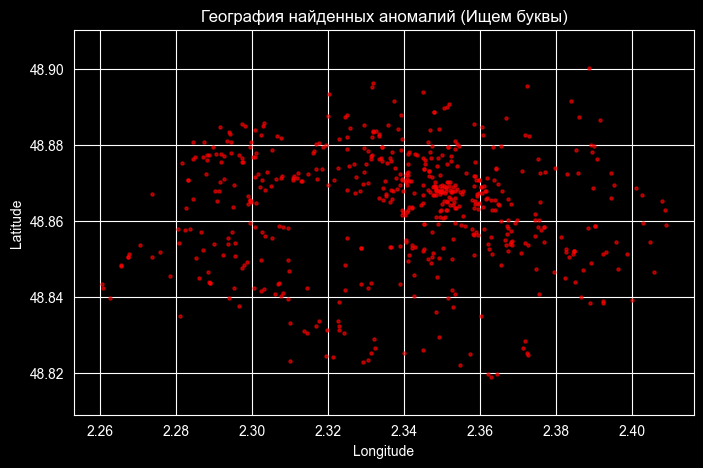

In [17]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

X = df[num_cols].fillna(df[num_cols].median())
X_scaled = StandardScaler().fit_transform(X)

iso = IsolationForest(contamination=0.02, random_state=42)
iso_labels = iso.fit_predict(X_scaled) # -1 = аномалия, 1 = норма
outliers_iso = df[iso_labels == -1]

print(f"Выделено {len(outliers_iso)} потенциальных аномалий через IsolationForest.")

if len(outliers_iso) > 0:
    plt.figure(figsize=(8, 5))
    plt.scatter(outliers_iso['longitude'], outliers_iso['latitude'], s=5, alpha=0.6, color='red')
    plt.title("География найденных аномалий (Ищем буквы)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.axis('equal')
    plt.show()

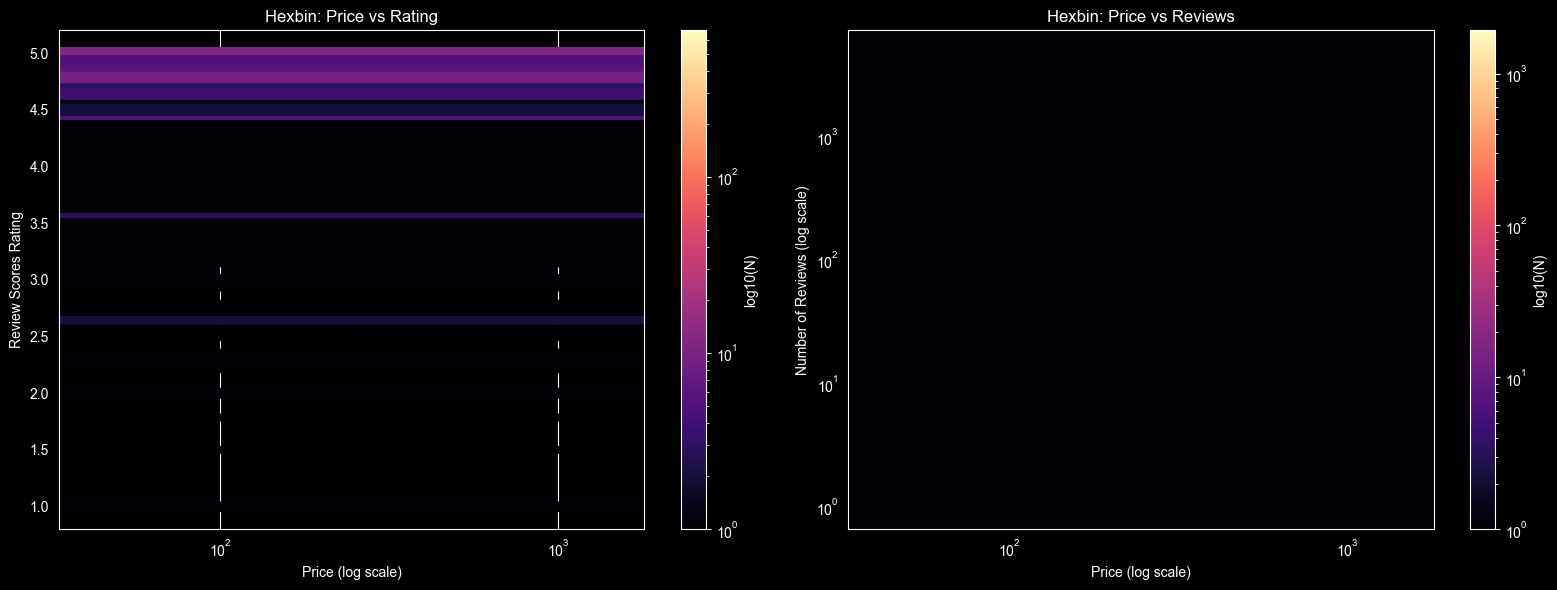

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

hb1 = axes[0].hexbin(df['price'], df['review_scores_rating'], gridsize=50, cmap='magma', bins='log')
axes[0].set_xscale('log')
axes[0].set_xlabel('Price (log scale)')
axes[0].set_ylabel('Review Scores Rating')
axes[0].set_title('Hexbin: Price vs Rating')
fig.colorbar(hb1, ax=axes[0], label='log10(N)')

hb2 = axes[1].hexbin(df['price'], df['number_of_reviews'], gridsize=50, cmap='magma', bins='log')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Price (log scale)')
axes[1].set_ylabel('Number of Reviews (log scale)')
axes[1].set_title('Hexbin: Price vs Reviews')
fig.colorbar(hb2, ax=axes[1], label='log10(N)')

plt.tight_layout()
plt.show()